# Sakila Video Rental Database Analysis
**Aaron Gabriel | ADS 507 Practical Data Engineering | Modules 3 and 4**

Explore a sample video rental business through its relational schema, SQL queries,
Python DataFrames, and a film-rating chart. The underlying Sakila database is
provided by Oracle; this project documents and analyzes that sample schema.

**Results provenance:** the displayed tables and chart are retained from the original
February 2, 2026 coursework run. This portfolio copy has not been executed. Its
connection code was rewritten to remove credentials and use SQLAlchemy with PyMySQL;
the five analytical SQL statements are unchanged. Execution counts have been cleared.

## 1. Rental workflow and scope
Module 3 documented how customers, rentals, payments, inventory, films, stores,
and staff relate. Module 4 queried the existing MySQL sample database from Python.
See [schema notes](docs/schema.md) for the relationship summary.

The business scenario motivates better stocking decisions, revenue visibility,
and customer retention. This notebook implements catalog and inventory analysis;
it does not measure retention or revenue, or implement a cloud pipeline.

## 2. Imports
Install the dependencies in `requirements.txt` using the README instructions.

In [ ]:
import os
from getpass import getpass

import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

## 3. Connection settings
Install Sakila separately using Oracle's official instructions. Use an existing
account with read access to that database. Settings come from `SAKILA_DB_*`
environment variables; the password can be entered privately when prompted.
`config.example.env` contains only non-secret example settings and is not loaded
automatically. Never display the engine URL or credentials in notebook output.

Creating the engine below does not open a connection; the first query does.
Connection setup in this prepared copy has not been tested against MySQL.

In [ ]:
db_user = os.environ.get("SAKILA_DB_USER")
if not db_user:
    raise ValueError("Set SAKILA_DB_USER to an existing account with Sakila read access.")

db_password = os.environ.get("SAKILA_DB_PASSWORD") or getpass("MySQL password: ")
db_url = URL.create(
    "mysql+pymysql",
    username=db_user,
    password=db_password,
    host=os.environ.get("SAKILA_DB_HOST", "127.0.0.1"),
    port=int(os.environ.get("SAKILA_DB_PORT", "3306")),
    database=os.environ.get("SAKILA_DB_NAME", "sakila"),
)
engine = create_engine(db_url, connect_args={"connect_timeout": 10})
del db_password, db_url

## 4. Inspect available tables and views
**Saved original output below.** Running this cell makes a new read-only database query.

In [ ]:
with engine.connect() as connection:
    table_names = pd.read_sql_query(text("SHOW TABLES"), connection)
table_names

,Tables_in_sakila
0,actor
1,actor_info
2,address
3,category
4,city
5,country
6,customer
7,customer_list
8,film
9,film_actor


## 5. Analytical queries
Each result below is a **saved original output**. The same five SQL statements
are available together in `sql/analysis.sql` for use with a MySQL client.

### 5.1. How many titles are in each film rating?

In [ ]:
films_by_rating_sql = """
SELECT rating, COUNT(*) AS film_count
FROM film
GROUP BY rating
ORDER BY film_count DESC;
"""

with engine.connect() as connection:
    films_by_rating = pd.read_sql_query(text(films_by_rating_sql), connection)
films_by_rating

,rating,film_count
0,PG-13,223
1,NC-17,210
2,R,195
3,PG,194
4,G,178


### 5.2. How many distinct titles have inventory records, by rating?

`COUNT(DISTINCT ...)` counts titles, not physical copies. Inventory records do not establish whether a copy is currently rented out.

In [ ]:
distinct_films_in_stock_sql = """
SELECT f.rating, COUNT(DISTINCT i.film_id) AS distinct_films_in_stock
FROM inventory i
JOIN film f ON f.film_id = i.film_id
GROUP BY f.rating
ORDER BY distinct_films_in_stock DESC;
"""

with engine.connect() as connection:
    distinct_films_in_stock = pd.read_sql_query(text(distinct_films_in_stock_sql), connection)
distinct_films_in_stock

,rating,distinct_films_in_stock
0,PG-13,213
1,NC-17,202
2,R,189
3,PG,183
4,G,171


### 5.3. How many titles have no inventory records?

The original result column is named `films_unavailable`. It means titles with **no inventory row**, not titles currently unavailable because every copy is on loan.

In [ ]:
films_unavailable_sql = """
SELECT COUNT(*) AS films_unavailable
FROM film f
LEFT JOIN inventory i ON f.film_id = i.film_id
WHERE i.film_id is NULL;
"""

with engine.connect() as connection:
    films_unavailable = pd.read_sql_query(text(films_unavailable_sql), connection)
films_unavailable

,films_unavailable
0,42


### 5.4. In which cities are stores located?

In [ ]:
store_cities_sql = """
SELECT DISTINCT c.city
FROM store s
JOIN address a ON s.address_id = a.address_id
JOIN city c ON a.city_id = c.city_id
ORDER BY c.city;
"""

with engine.connect() as connection:
    store_cities = pd.read_sql_query(text(store_cities_sql), connection)
store_cities

,city
0,Lethbridge
1,Woodridge


### 5.5. Which actor appearing in every category has the most distinct films?

The `HAVING` clause requires coverage of every category. `LIMIT 1` returns one top result; tied actors are not all listed.

In [ ]:
top_actor_all_categories_sql = """
SELECT 
    a.actor_id,
    a.first_name,
    a.last_name,
    COUNT(DISTINCT fa.film_id) AS film_count
FROM actor a
JOIN film_actor fa ON a.actor_id = fa.actor_id
JOIN film_category fc ON fa.film_id = fc.film_id
GROUP BY a.actor_Id, a.first_name, a.last_name
HAVING COUNT(DISTINCT fc.category_id) = (SELECT COUNT(*)FROM category)
ORDER BY film_count DESC
LIMIT 1;
"""

with engine.connect() as connection:
    top_actor_all_categories = pd.read_sql_query(text(top_actor_all_categories_sql), connection)
top_actor_all_categories

,actor_id,first_name,last_name,film_count
0,107,GINA,DEGENERES,42


## 6. Visualize the rating distribution
**Saved original chart below.** Ratings are discrete categories, so a bar chart
makes their title counts easy to compare. The chart was not regenerated during preparation.

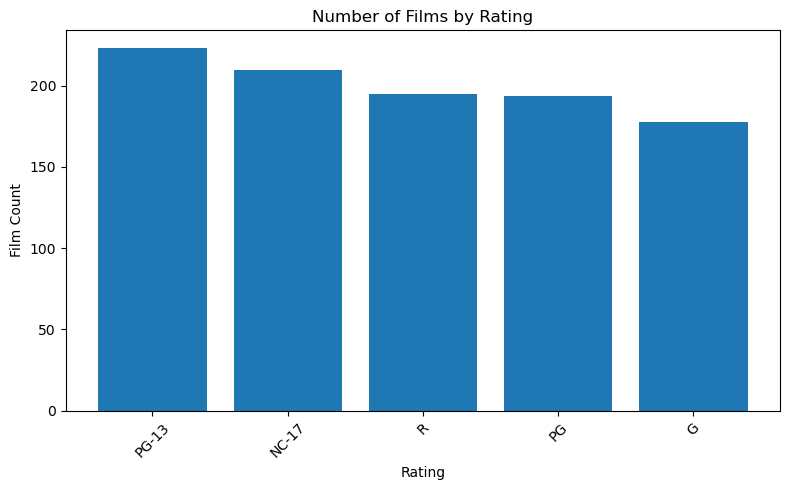

In [ ]:
#Bar chart: number of films by rating

plt.figure(figsize = (8,5))
plt.bar(films_by_rating['rating'], films_by_rating['film_count'])

plt.title("Number of Films by Rating")
plt.xlabel("Rating")
plt.ylabel("Film Count")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Findings and interpretation
- The saved rating counts sum to **1,000 films**; **PG-13** is the largest group at **223**.
- The distinct titles with inventory records sum to **958**; **42** titles have no inventory record.
- The stores are in **Lethbridge** and **Woodridge** in the sample data.
- The all-category actor query returns **Gina Degeneres**, with **42** distinct films.

These describe a sample dataset and the original run, not a live business.
Query results may differ with another Sakila release or modified data.

### Reflection from the original submission
Using a notebook made it straightforward to connect SQL results to DataFrames
and then visualize the rating distribution. The bar chart helped confirm the
relative counts more clearly than reading the result table alone.

### Attribution and preparation
Oracle supplies the Sakila schema and sample records. Aaron's coursework provides
the business framing, relationship discussion, SQL analysis, and visualization.
OpenAI Codex assisted with the sanitized portfolio packaging, connection refactor,
documentation, and static checks. This preparation did not rerun the analysis.
See `docs/validation.md` for validation scope and limitations.

In [ ]:
engine.dispose()